# Figure 3: sample relationships

This notebook reproduces the two-panel design in 05_analysis/Figure3_sample_relationship.py, while deriving the Pearson matrix from the packaged TMM log2-CPM data. Run Restart Kernel and Run All from the release root or figures/. NumPy, pandas and Matplotlib are required. Only the last cell writes files.

| Panel | Release input | Definition used by 05_analysis |
|---|---|---|
| a | input_data/fig3a.pca_scores.tsv | Workflow PCA on the complete retained TMM log2-CPM matrix, centered and not variance-scaled; all 27 PC scores determine explained variance. No point labels. |
| b | input_data/fig3b.transformed_expression.tsv | Same matrix as data_records/4. potato_gene_log2CPM.tsv. The top 500 nonzero-MAD genes give Pearson correlations. **Display samples in sampling-time order**, without heatmap clustering. |
| both | ../data_records/1. sample_metadata.tsv | Sample IDs, times and replicates. |

The workflow computes hierarchical clustering for a separate result, but the 05_analysis Figure 3 renderer retains input sample order in its heatmap. Its cividis scale is fixed at −0.1 to 1.0.

### Figure production settings

The assembled figure is 180 mm wide. All figure text is 6 pt Arial and the PDF embeds editable TrueType text. Discrete colours follow the colour-blind-accessible example in the [Nature research figure guide](https://research-figure-guide.nature.com/figures/building-and-exporting-figure-panels/); neutral grey distinguishes the ninth time point. The correlation heatmap uses a colour-blind-friendly cividis scale. Use the vector PDF for manuscript submission; PNG is a 600 dpi preview.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def locate_figures():
    for candidate in (Path.cwd(), Path.cwd() / "figures"):
        if (candidate/"input_data").is_dir() and (candidate.parent/"data_records"/"1. sample_metadata.tsv").is_file():
            return candidate.resolve()
    raise FileNotFoundError("Start from the release root or figures directory")

FIGURES = locate_figures()
INPUT = FIGURES/"input_data"
metadata = pd.read_csv(FIGURES.parent/"data_records"/"1. sample_metadata.tsv",sep="\t",usecols=["sample_id","time_h","biological_replicate","treatment"])
if len(metadata)!=27 or metadata.sample_id.duplicated().any():
    raise ValueError("Expected 27 unique metadata samples")
metadata = metadata.sort_values(["time_h","biological_replicate"]).reset_index(drop=True)
SAMPLES = metadata.sample_id.tolist()
metadata["label"] = metadata.apply(lambda r: f"Mock-{int(r.biological_replicate)}" if int(r.time_h)==0 else f"{int(r.time_h)}hpi-{int(r.biological_replicate)}",axis=1)
TIME_COLORS = dict(zip(sorted(metadata.time_h.unique()),["#000000","#56B4E9","#009E73","#0072B2","#F0E442","#E69F00","#D55E00","#CC79A7","#666666"]))

def align_samples(data):
    if data.sample_id.duplicated().any() or set(data.sample_id)!=set(SAMPLES):
        raise ValueError("Sample IDs disagree with metadata")
    return metadata.merge(data,on="sample_id",validate="one_to_one").sort_values(["time_h","biological_replicate"]).reset_index(drop=True)

STYLE={"font_size":6,"png_dpi":600}
plt.rcParams.update({"font.family":"Arial","font.size":STYLE["font_size"],"pdf.fonttype":42})
print(f"Input: {FIGURES}; samples: {len(SAMPLES)}")


from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
ANALYSIS={"top_variable_genes":500,"variability_metric":"R MAD (constant 1.4826)","correlation_method":"pearson","display_order":"sampling time"}
STYLE.update({"figure_size":(180/25.4,100/25.4),"point_size":28})

def padded_limits(values):
    low=float(np.min(values)); high=float(np.max(values))
    span=max(high-low,abs(high)*.06,.5)
    return low-.16*span,high+.16*span


Input: C:\Users\Txieb\Desktop\RNA-seq_PotatoPi_Release\figures; samples: 27


## Panel a: PCA scores

Variance percentages come from all PC columns in the supplied scores, never hard-coded.


In [2]:
def prepare_panel_a(path):
    scores=pd.read_csv(path,sep="\t").rename(columns={"sample":"sample_id"})
    pcs=sorted([x for x in scores if x.startswith("PC") and x[2:].isdigit()],key=lambda x:int(x[2:]))
    if pcs!=[f"PC{i}" for i in range(1,28)]: raise ValueError("Expected PC1–PC27")
    scores=align_samples(scores)
    if not np.isfinite(scores[pcs].to_numpy()).all(): raise ValueError("Non-finite PCA scores")
    variance=scores[pcs].var(axis=0,ddof=1)
    explained=(100*variance/variance.sum()).rename("explained_variance_percent").reset_index().rename(columns={"index":"component"})
    return scores,explained
panel_a,explained=prepare_panel_a(INPUT/"fig3a.pca_scores.tsv")
display(explained.head())


,component,explained_variance_percent
0,PC1,44.604317
1,PC2,20.179936
2,PC3,10.452784
3,PC4,7.235191
4,PC5,3.250686


In [3]:
A_STYLE={"point_size":28}
def plot_panel_a(ax,data,variance,style):
    """Reproduce the unlabelled PCA scatter and time legend in Figure3_sample_relationship.py."""
    times=sorted(data.time_h.unique())
    for time in times:
        group=data[data.time_h==time]
        ax.scatter(group.PC1,group.PC2,s=style["point_size"],color=TIME_COLORS[time],
                   edgecolors="#333333",linewidths=.35,zorder=3)
    ax.axhline(0,color="#D2D2D2",linestyle=(0,(4,3)),lw=.55)
    ax.axvline(0,color="#D2D2D2",linestyle=(0,(4,3)),lw=.55)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.set_xlim(*padded_limits(data.PC1)); ax.set_ylim(*padded_limits(data.PC2))
    v=dict(zip(variance.component,variance.explained_variance_percent))
    ax.set_xlabel(f"PC1 ({v['PC1']:.1f}%)",fontsize=6,labelpad=4)
    ax.set_ylabel(f"PC2 ({v['PC2']:.1f}%)",fontsize=6,labelpad=4)
    ax.set_title("a  Principal component analysis",loc="left",fontsize=6,fontweight="bold",pad=7)
    legend_order=list(range(len(times)))
    ax.legend(handles=[Line2D([],[],marker="o",linestyle="",color=TIME_COLORS[times[i]],markersize=3.5,markeredgecolor="#333333",markeredgewidth=.35,label=("Mock" if int(times[i])==0 else f"{int(times[i])} hpi")) for i in legend_order],
              frameon=False,ncol=1,fontsize=6,handlelength=.9,columnspacing=.65,
              loc="upper left",bbox_to_anchor=(1.02,1))
    return ax


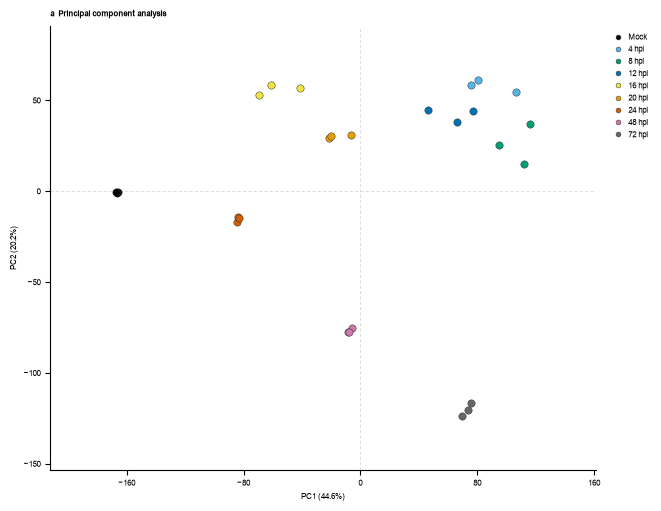

In [4]:
preview,ax=plt.subplots(figsize=(6.5,5),layout="constrained")
plot_panel_a(ax,panel_a,explained,A_STYLE)
plt.show()


## Panel b: sample correlation in input order

R's MAD uses 1.4826 × median absolute deviation. The 500 highest nonzero-MAD genes determine Pearson correlation. The heatmap then keeps the metadata sampling-time order, as in 05_analysis/Figure3_sample_relationship.py; it does **not** cluster the matrix.


In [5]:
def prepare_panel_b(path):
    expression=pd.read_csv(path,sep="\t")
    if expression.columns[0]!="gene_id" or expression.gene_id.duplicated().any(): raise ValueError("Invalid gene IDs")
    if set(expression.columns[1:])!=set(SAMPLES): raise ValueError("Expression samples disagree with metadata")
    matrix=expression.set_index("gene_id")[SAMPLES]
    if not np.isfinite(matrix.to_numpy()).all(): raise ValueError("Non-finite expression")
    median=matrix.median(axis=1)
    mad=matrix.sub(median,axis=0).abs().median(axis=1)*1.4826
    ranked=mad[mad>0].sort_values(ascending=False,kind="stable").head(ANALYSIS["top_variable_genes"])
    if len(ranked)!=500: raise ValueError("Fewer than 500 nonzero-MAD genes")
    selected=ranked.rename("mad_log2cpm").reset_index()
    selected.insert(0,"rank",np.arange(1,len(selected)+1))
    correlation=matrix.loc[ranked.index].corr(method=ANALYSIS["correlation_method"])
    values=correlation.to_numpy()
    if not np.isfinite(values).all() or not np.allclose(values,values.T,atol=1e-12) or not np.allclose(np.diag(values),1,atol=1e-12):
        raise ValueError("Invalid sample correlation")
    sample_order=pd.DataFrame({"heatmap_position":np.arange(1,len(SAMPLES)+1),"sample_id":SAMPLES})
    return correlation,selected,sample_order
panel_b,selected_genes,sample_order=prepare_panel_b(INPUT/"fig3b.transformed_expression.tsv")
display(selected_genes.head())


,rank,gene_id,mad_log2cpm
0,1,PGSC0003DMG400007375,6.318102
1,2,PGSC0003DMG400013415,6.127990
2,3,PGSC0003DMG400013416,6.051939
3,4,PGSC0003DMG400013461,5.893115
4,5,PGSC0003DMG400016695,5.284672


In [6]:
B_STYLE={"cmap":"cividis","vmin":-0.1,"vmax":1.0}
def plot_panel_b(ax,correlation,order,style):
    """Plot Pearson correlation in the supplied sample order, without clustering."""
    names=order.sample_id.tolist()
    values=correlation.loc[names,names].to_numpy()
    image=ax.imshow(values,cmap=style["cmap"],norm=Normalize(vmin=style["vmin"],vmax=style["vmax"]),
                    interpolation="nearest",aspect="equal")
    positions=np.arange(len(names))
    labels=[f"Mock-{int(r.biological_replicate)}" if int(r.time_h)==0 else f"{int(r.time_h)}hpi-{int(r.biological_replicate)}" for r in metadata.itertuples()]
    ax.set_xticks(positions,labels,rotation=90,fontsize=6)
    ax.set_yticks(positions,labels,fontsize=6)
    ax.tick_params(axis="both",width=.45,length=1.8,pad=1.2)
    boundaries=np.cumsum(metadata.groupby("time_h",sort=True).size().to_numpy())[:-1]
    for boundary in boundaries:
        ax.axhline(boundary-.5,color="white",lw=.65)
        ax.axvline(boundary-.5,color="white",lw=.65)
    ax.set_title("b  Sample correlation",loc="left",fontsize=6,fontweight="bold",pad=7)
    return image


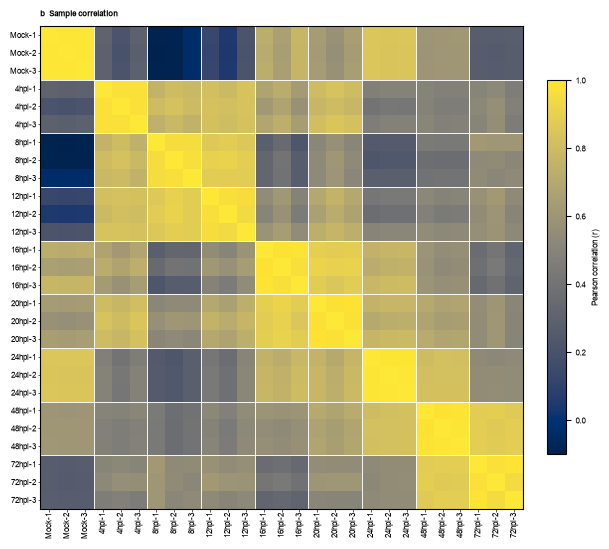

In [7]:
preview,ax=plt.subplots(figsize=(6,5.5),layout="constrained")
image=plot_panel_b(ax,panel_b,sample_order,B_STYLE)
preview.colorbar(image,ax=ax,label="Pearson correlation (r)",shrink=0.72)
plt.show()


## Assemble and export Figure 3

The layout and color scale follow 05_analysis/Figure3_sample_relationship.py. The full matrix and order table are exported with the same time ordering shown on the heatmap.


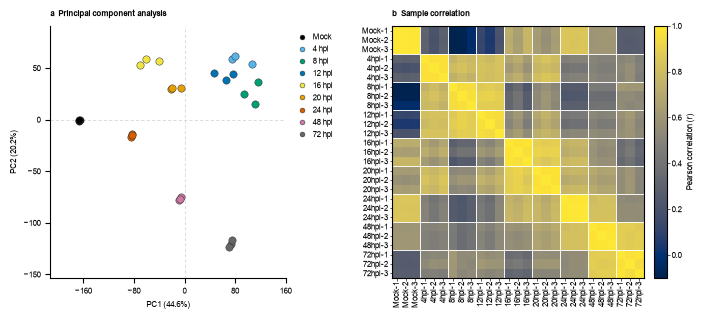

In [8]:
fig=plt.figure(figsize=STYLE["figure_size"],facecolor="white")
grid=fig.add_gridspec(1,2,width_ratios=[.92,1.10],left=.07,right=.94,top=.85,bottom=.21,wspace=.38)
ax_a=fig.add_subplot(grid[0,0]); ax_b=fig.add_subplot(grid[0,1])
plot_panel_a(ax_a,panel_a,explained,A_STYLE)
image=plot_panel_b(ax_b,panel_b,sample_order,B_STYLE)
bar=fig.colorbar(image,ax=ax_b,fraction=.046,pad=.035)
bar.ax.tick_params(labelsize=6,width=.45,length=2.2,pad=1.5)
bar.set_label("Pearson correlation (r)",fontsize=6,labelpad=3)
plt.show()


In [9]:
outdir=FIGURES/"output"/"fig3"; source_dir=outdir/"source_data"
source_dir.mkdir(parents=True,exist_ok=True)
fig.savefig(outdir/"Fig3.png",dpi=STYLE["png_dpi"],facecolor="white")
try:
    fig.savefig(outdir/"Fig3.pdf",facecolor="white")
except PermissionError:
    fig.savefig(outdir/"Fig3_updated.pdf",facecolor="white")
    print("Fig3.pdf is open in another application; saved Fig3_updated.pdf")
panel_a[["sample_id","time_h","biological_replicate",*[f"PC{i}" for i in range(1,28)]]].to_csv(source_dir/"Fig3a_pca_scores.tsv",sep="\t",index=False,float_format="%.17g",lineterminator="\n")
explained.to_csv(source_dir/"Fig3a_explained_variance.tsv",sep="\t",index=False,float_format="%.17g",lineterminator="\n")
panel_b.to_csv(source_dir/"Fig3b_sample_correlation.tsv",sep="\t",index=True,index_label="sample_id",float_format="%.17g",lineterminator="\n")
selected_genes.to_csv(source_dir/"Fig3b_selected_genes.tsv",sep="\t",index=False,float_format="%.17g",lineterminator="\n")
sample_order.to_csv(source_dir/"Fig3b_sample_order.tsv",sep="\t",index=False,lineterminator="\n")
print(f"Exported {outdir}")


Exported C:\Users\Txieb\Desktop\RNA-seq_PotatoPi_Release\figures\output\fig3
